# Iris Species Classification — ANN with Softmax Output
Architecture: **Dense(32, relu) → Dense(16, relu) → Dense(n_classes, softmax)**, compiled with **Adam** and **sparse_categorical_crossentropy**, trained for 30 epochs.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow info logs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)   # reproducible weights and shuffling

## 1. Load and check the data

In [2]:
df = pd.read_csv('Iris.csv')
print(df.shape)
df.head()

(150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print(df.isnull().sum())
print('\nDuplicates:', df.duplicated().sum())
print('\n', df['Species'].value_counts())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicates: 0

 Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 2. Prepare features and target
`Id` is just a row number, so it is dropped. `Species` is text, so it is label-encoded to 0, 1, 2.

In [4]:
df = df.drop(columns=['Id'])

le = LabelEncoder()
df['Species'] = le.fit_transform(df['Species'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

X = df.drop(columns=['Species'])
y = df['Species']
n_classes = y.nunique()
print('n_classes:', n_classes)

{'Iris-setosa': np.int64(0), 'Iris-versicolor': np.int64(1), 'Iris-virginica': np.int64(2)}
n_classes: 3


## 3. Train/test split and scaling

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled = scaler.transform(X_test)

print('Train:', X_train_scaled.shape, '| Test:', X_test_scaled.shape)

Train: (120, 4) | Test: (30, 4)


## 4. Build and compile the ANN

In [6]:
model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),   # 4 input features
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',   # integer labels 0/1/2, no one-hot needed
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 739 (2.89 KB)

 Trainable params: 739 (2.89 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train
20% of the training set is held out as validation data to track accuracy and loss each epoch; the test set is used only once at the end.

In [7]:
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=8,
    verbose=2   # one line per epoch
)

Epoch 1/30


12/12 - 1s - 91ms/step - accuracy: 0.5521 - loss: 0.9581 - val_accuracy: 0.6667 - val_loss: 0.9042


Epoch 2/30


12/12 - 0s - 7ms/step - accuracy: 0.8021 - loss: 0.8166 - val_accuracy: 0.7083 - val_loss: 0.7975


Epoch 3/30


...

12/12 - 0s - 7ms/step - accuracy: 0.9583 - loss: 0.1550 - val_accuracy: 1.0000 - val_loss: 0.1221


Epoch 29/30


12/12 - 0s - 7ms/step - accuracy: 0.9583 - loss: 0.1498 - val_accuracy: 1.0000 - val_loss: 0.1149


Epoch 30/30


12/12 - 0s - 7ms/step - accuracy: 0.9583 - loss: 0.1448 - val_accuracy: 1.0000 - val_loss: 0.1083


## 6. Test accuracy

In [8]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f'Test loss    : {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

Test loss    : 0.1804
Test accuracy: 0.9000


In [9]:
probs = model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(probs, axis=1)   # class with the highest softmax probability

print(classification_report(y_test, y_pred, target_names=le.classes_))
print(pd.DataFrame(confusion_matrix(y_test, y_pred),
                   index=[f'actual {c}' for c in le.classes_],
                   columns=[f'pred {c}' for c in le.classes_]))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.89      0.80      0.84        10
 Iris-virginica       0.82      0.90      0.86        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30

                        pred Iris-setosa  pred Iris-versicolor  \
actual Iris-setosa                    10                     0   
actual Iris-versicolor                 0                     8   
actual Iris-virginica                  0                     1   

                        pred Iris-virginica  
actual Iris-setosa                        0  
actual Iris-versicolor                    2  
actual Iris-virginica                     9  


In [10]:
# Softmax outputs for the first 5 test samples — each row sums to 1
pd.DataFrame(probs[:5], columns=le.classes_).round(3).assign(Sum=probs[:5].sum(axis=1).round(3))

,Iris-setosa,Iris-versicolor,Iris-virginica,Sum
0,0.995,0.005,0.000,1.0
1,0.002,0.134,0.864,1.0
2,0.094,0.899,0.007,1.0
3,0.037,0.958,0.006,1.0
4,0.996,0.004,0.000,1.0


## 7. Training vs. validation accuracy and loss

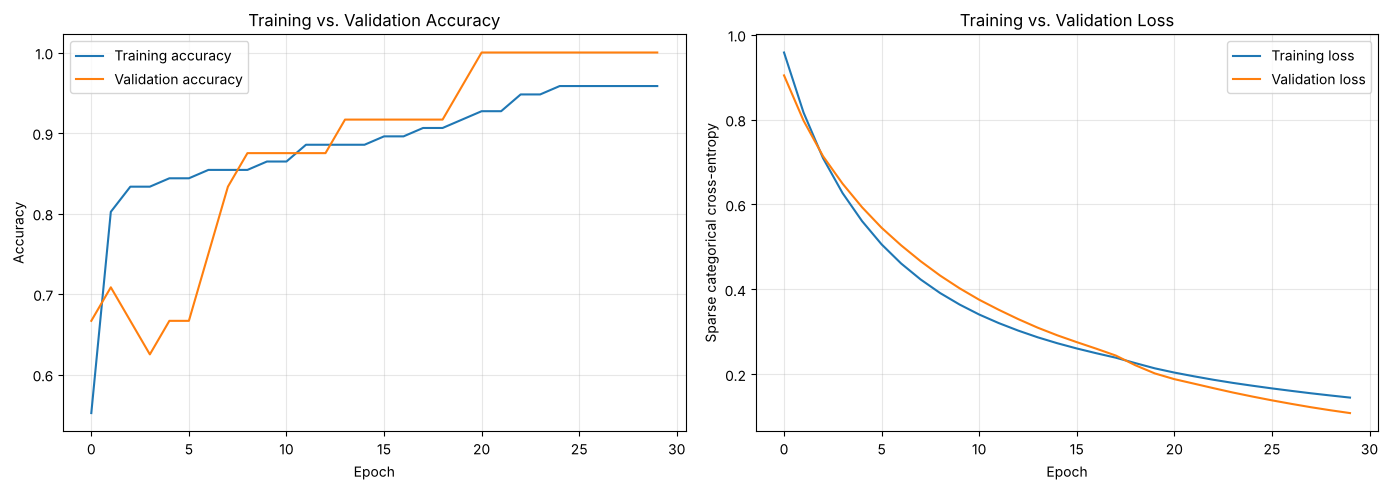

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Training accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Training vs. Validation Accuracy')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='Training loss')
axes[1].plot(history.history['val_loss'], label='Validation loss')
axes[1].set_title('Training vs. Validation Loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Sparse categorical cross-entropy')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Results
- **Final test accuracy: 0.90** (27 of 30 correct). Setosa is classified perfectly; the 3 errors are all between versicolor and virginica, the two species whose measurements overlap.
- **Curves:** training and validation loss fall together with no gap, so there is no overfitting. Validation accuracy reaches 1.0 by epoch 21, but the validation set is only 24 flowers, so each one is worth about 4%.
- Both losses are still falling at epoch 30, so the model has not fully converged; a few more epochs would likely help it separate versicolor and virginica better.

## Why Softmax and not Sigmoid?
This is a **multi-class** problem where each flower belongs to exactly one of three species, so Softmax is used to turn the three output scores into probabilities that compete with each other and **sum to 1**, and the predicted class is the one with the highest probability. Sigmoid would score each class independently (0–1 each, not summing to 1), which suits binary or multi-label problems, not choosing a single class out of several.